<a href="https://colab.research.google.com/github/shruti-dhaigude/CODSOFT_TASK1/blob/main/CODSOFT_TASK3_Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customer Churn Prediction

Introduction

Customer churn refers to the situation in which customers stop using a company's products or services. It is a major challenge for subscription-based businesses because losing customers can reduce revenue and affect business growth.

The objective of this project is to develop a machine learning model that predicts whether a customer is likely to leave a service. The project uses the IBM Telco Customer Churn dataset, which contains customer demographic information, service details, contract types, tenure, and billing information.

Two machine learning algorithms, Logistic Regression and Random Forest, are implemented and evaluated using accuracy, precision, recall, and F1-score. The models are compared to identify which performs better on the test dataset.

This project demonstrates how machine learning can help businesses identify customers at risk of churning and develop effective customer retention strategies.

Project Objectives

1. To analyze customer data and identify patterns related to customer churn.
2. To clean and preprocess the dataset for machine learning.
3. To build churn prediction models using Logistic Regression and Random Forest.
4. To evaluate and compare the models using accuracy, precision, recall, and F1-score.
5. To identify important factors that influence churn predictions and help businesses improve customer retention.

Project Description and Dataset

This project uses the IBM Telco Customer Churn dataset, which contains information about 7,043 customer records and 21 original columns.

The dataset includes customer details, subscribed services, contract information, monthly charges, total charges, and churn status.

- Input features: Customer tenure, monthly charges, contract type, payment method, and other customer information.
- Target variable: "Churn"
- Prediction classes: "Yes" (customer leaves) and "No" (customer stays).
- Machine learning algorithms: Logistic Regression and Random Forest.

During preprocessing, 11 records with missing "TotalCharges" values were removed, and the "customerID" column was excluded because it is an identifier rather than a useful predictive feature. Categorical variables were converted into numerical features before training the models.

In [1]:

# CODSOFT TASK 3: CUSTOMER CHURN PREDICTION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


Methodology

The project was completed using the following steps:

1. Data Collection: Loaded the Telco Customer Churn dataset using Pandas.
2. Data Exploration: Examined the dataset structure, data types, missing values, duplicate records, and churn distribution.
3. Data Preprocessing: Converted "TotalCharges" into a numeric format, removed 11 records with missing values, and dropped the "customerID" column.
4. Feature Encoding: Converted categorical variables into numerical features using one-hot encoding.
5. Data Splitting: Divided the dataset into 80% training data and 20% testing data.
6. Model Training: Trained Logistic Regression and Random Forest classification models.
7. Model Evaluation: Compared both models using accuracy, precision, recall, F1-score, and confusion matrices.
8. Feature Importance: Analyzed the Random Forest model's feature importance scores to identify the most influential predictive features.

Tools and Libraries: Python, Google Colab, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

Results and Model Comparison

Two machine learning classification algorithms were trained and evaluated on the test dataset.

Evaluation Metric| Logistic Regression| Random Forest
Accuracy| 80.38%| 79.03%
Precision| 64.76%| 63.30%
Recall| 57.49%| 50.27%
F1-Score| 60.91%| 56.04%

Result Analysis

Logistic Regression performed better than Random Forest across all four evaluation metrics in this experiment. It achieved an accuracy of 80.38%, meaning it correctly classified approximately 80% of the test records.

The recall for the churn class was 57.49% for Logistic Regression and 50.27% for Random Forest. This indicates that both models missed some customers who actually churned. Therefore, improving churn detection recall could be an important direction for future work.

Based on these results, Logistic Regression was the better-performing model among the two algorithms tested.

Key Findings

1. Logistic Regression achieved the highest accuracy of 80.38% among the two models tested.
2. Logistic Regression also achieved higher precision, recall, and F1-score than Random Forest.
3. "TotalCharges", "tenure", and "MonthlyCharges" were the three most important features according to the Random Forest feature importance analysis.
4. Customer churn prediction can help businesses identify customers who may leave their services and plan suitable retention strategies.
5. The models can be improved further through hyperparameter tuning, threshold optimization, and testing additional algorithms.

Limitations

The model was evaluated on a single train-test split, and its predictions are not guaranteed to generalize to every business or customer population. Feature importance indicates predictive contribution within the trained Random Forest model; it does not establish that a feature causes customer churn.

In [2]:

# STEP 3: LOAD THE CUSTOMER CHURN DATASET

url = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    print("\nFirst five rows:")
    display(df.head())
except Exception as e:
    print("Error loading dataset:", e)

Error loading dataset: HTTP Error 404: Not Found


In [3]:

# STEP 3: LOAD CUSTOMER CHURN DATASET

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

HTTPError: HTTP Error 404: Not Found

In [4]:

# STEP 3: LOAD CUSTOMER CHURN DATASET

url = "https://raw.githubusercontent.com/SohelRaja/Customer-Churn-Analysis/master/Datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

# STEP 4: INSPECT THE DATASET

print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [6]:

# STEP 5: CLEAN AND PREPARE THE DATA

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values created during conversion
print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isnull().sum())

# Remove rows with missing TotalCharges
df.dropna(subset=["TotalCharges"], inplace=True)

# Remove customerID because it is an identifier, not a useful predictor
df.drop(columns=["customerID"], inplace=True)

# Convert the target variable into numbers
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("\nData cleaned successfully!")
print("Dataset shape:", df.shape)
print("\nUpdated data types:")
print(df.dtypes)
print("\nChurn counts:")
print(df["Churn"].value_counts())

Missing TotalCharges after conversion: 11

Data cleaned successfully!
Dataset shape: (7032, 20)

Updated data types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

Churn counts:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [7]:

# STEP 6: ENCODE CATEGORICAL FEATURES

# Separate input features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Feature encoding completed!")
print("Number of input features:", X.shape[1])
print("Number of target values:", y.shape[0])

print("\nFirst five encoded rows:")
display(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Feature encoding completed!
Number of input features: 30
Number of target values: 7032

First five encoded rows:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0



Target distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [8]:

# STEP 7: SPLIT DATA INTO TRAINING AND TESTING SETS

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nChurn proportion in training data:")
print(y_train.value_counts(normalize=True).round(3))

print("\nChurn proportion in testing data:")
print(y_test.value_counts(normalize=True).round(3))

Data splitting completed!
Training features: (5625, 30)
Testing features: (1407, 30)
Training target: (5625,)
Testing target: (1407,)

Churn proportion in training data:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64

Churn proportion in testing data:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


In [9]:

# STEP 8: TRAIN LOGISTIC REGRESSION MODEL

# Scale the numerical features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and train the model
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

# Predict customer churn
lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")
print("Predictions completed!")
print("Number of predictions:", len(lr_predictions))

Logistic Regression model trained successfully!
Predictions completed!
Number of predictions: 1407


LOGISTIC REGRESSION - RESULTS
-----------------------------------
Accuracy:  0.8038
Precision: 0.6476
Recall:    0.5749
F1-Score:  0.6091

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1033
     Churned       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



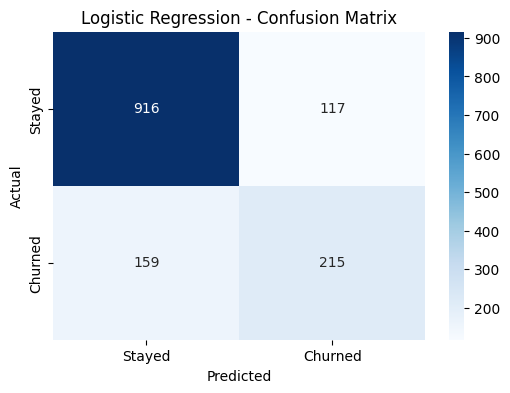

In [10]:

# STEP 9: EVALUATE LOGISTIC REGRESSION

lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions)
lr_recall = recall_score(y_test, lr_predictions)
lr_f1 = f1_score(y_test, lr_predictions)

print("LOGISTIC REGRESSION - RESULTS")
print("-" * 35)
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-Score:  {lr_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Stayed", "Churned"]
))

# Plot the confusion matrix
cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [11]:

# STEP 10: TRAIN RANDOM FOREST MODEL

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

# Predict customer churn
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("Predictions completed!")
print("Number of predictions:", len(rf_predictions))

Random Forest model trained successfully!
Predictions completed!
Number of predictions: 1407


RANDOM FOREST - RESULTS
-----------------------------------
Accuracy:  0.7903
Precision: 0.6330
Recall:    0.5027
F1-Score:  0.5604

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.83      0.89      0.86      1033
     Churned       0.63      0.50      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



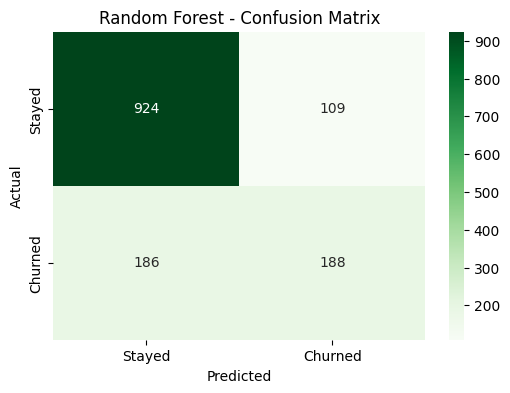

In [12]:

# STEP 11: EVALUATE RANDOM FOREST

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print("RANDOM FOREST - RESULTS")
print("-" * 35)
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Stayed", "Churned"]
))

# Plot confusion matrix
cm_rf = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8038,0.6476,0.5749,0.6091
1,Random Forest,0.7903,0.6330,0.5027,0.5604


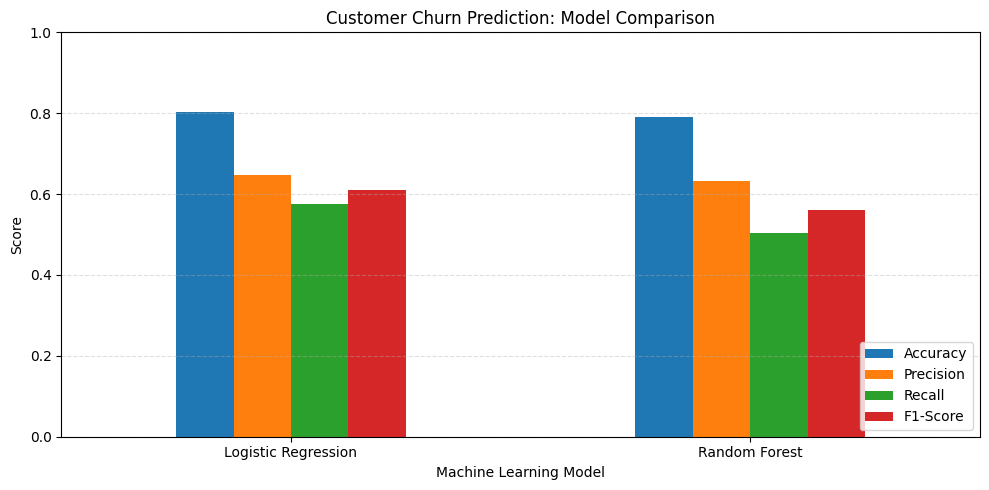

In [13]:

# STEP 12: COMPARE BOTH MODELS

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [lr_accuracy, rf_accuracy],
    "Precision": [lr_precision, rf_precision],
    "Recall": [lr_recall, rf_recall],
    "F1-Score": [lr_f1, rf_f1]
})

print("MODEL COMPARISON")
display(results.round(4))

# Plot metric comparison
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Customer Churn Prediction: Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

TOP 10 FEATURES INFLUENCING CHURN PREDICTION


,Feature,Importance
3,TotalCharges,0.1786
1,tenure,0.1620
2,MonthlyCharges,0.1519
25,Contract_Two year,0.0607
10,InternetService_Fiber optic,0.0389
28,PaymentMethod_Electronic check,0.0379
24,Contract_One year,0.0306
13,OnlineSecurity_Yes,0.0291
4,gender_Male,0.0255
26,PaperlessBilling_Yes,0.0235


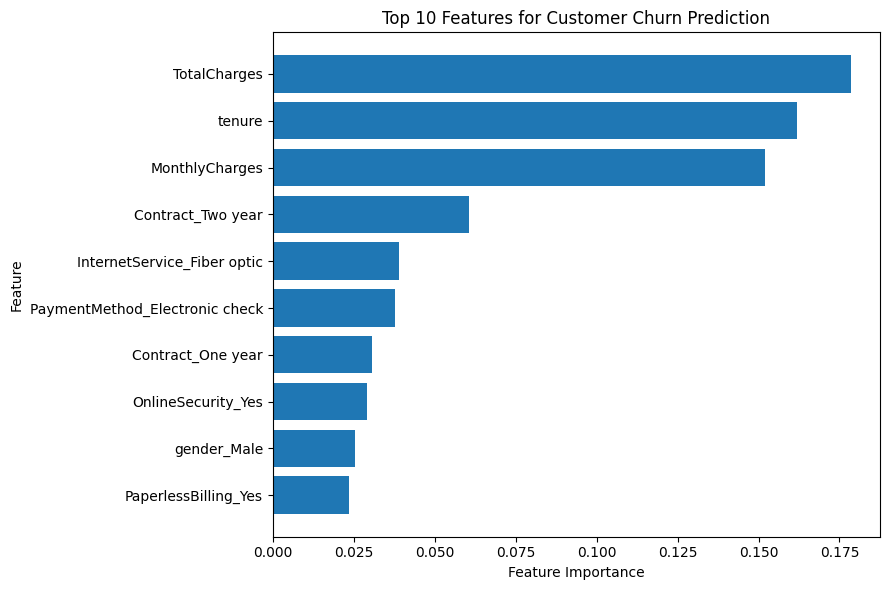

In [14]:

# STEP 13: FEATURE IMPORTANCE ANALYSIS

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 10 FEATURES INFLUENCING CHURN PREDICTION")
display(importance.head(10).round(4))

# Plot top 10 features
top10 = importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.title("Top 10 Features for Customer Churn Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Conclusion

In this project, a Customer Churn Prediction system was developed using machine learning techniques and the IBM Telco Customer Churn dataset. The dataset was cleaned, categorical variables were encoded, and the data was divided into training and testing sets.

Two classification algorithms, Logistic Regression and Random Forest, were trained and evaluated using accuracy, precision, recall, and F1-score.

Logistic Regression achieved an accuracy of 80.38%, precision of 64.76%, recall of 57.49%, and F1-score of 60.91%. Random Forest achieved an accuracy of 79.03%, precision of 63.30%, recall of 50.27%, and F1-score of 56.04%.

Based on these results, Logistic Regression performed better than Random Forest on all four evaluation metrics in this experiment. The feature importance analysis identified TotalCharges, tenure, and MonthlyCharges as the three most important features used by the Random Forest model.

This project demonstrates how machine learning can help subscription-based businesses identify customers who may be likely to leave and support customer retention strategies. Further improvements could include hyperparameter tuning, threshold optimization, and testing additional classification algorithms.